# M's Approach

In this project our goal is to clasify the "Default_Risk" of customers based on the features of the dataset. This dataset is sourced from Kaggle and contains 10000 rows and 11 columns.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

In [2]:
df = pd.read_csv("data/BNPL_Financial_Default_Risk_Dataset.csv")

**EDA**

In [3]:
df.shape

(10000, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Customer_ID                      10000 non-null  str    
 1   Age                              10000 non-null  int64  
 2   Employment_Status                10000 non-null  str    
 3   Income_USD                       9695 non-null   float64
 4   Credit_Score                     9702 non-null   float64
 5   Total_BNPL_Active_Loans          10000 non-null  int64  
 6   Total_BNPL_Debt_USD              10000 non-null  int64  
 7   Late_Payment_History             10000 non-null  str    
 8   Shopping_Category_Most_Frequent  10000 non-null  str    
 9   Average_Transaction_Value_USD    10000 non-null  int64  
 10  Default_Risk                     10000 non-null  str    
dtypes: float64(2), int64(4), str(5)
memory usage: 859.5 KB


In [5]:
df.head()

,Customer_ID,Age,Employment_Status,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Late_Payment_History,Shopping_Category_Most_Frequent,Average_Transaction_Value_USD,Default_Risk
0,C00001,29,Employed,73405.0,637.0,2,193,No,Fashion,118,Low
1,C00002,64,Employed,53732.0,815.0,0,0,No,Electronics,662,Low
2,C00003,26,Freelancer,69930.0,723.0,2,273,No,Fashion,76,Low
3,C00004,19,Employed,96941.0,716.0,3,421,No,Home/Furniture,449,Low
4,C00005,55,Student,15959.0,675.0,2,145,No,Travel,974,Low


In [6]:
df.describe()

,Age,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Average_Transaction_Value_USD
count,10000.000000,9695.000000,9702.000000,10000.000000,10000.000000,10000.000000
mean,34.248300,53981.142651,663.671408,2.317000,348.805100,331.807700
std,12.911441,29797.373960,76.221869,1.854469,315.096249,264.360624
min,18.000000,5000.000000,300.000000,0.000000,0.000000,10.000000
25%,23.000000,21996.500000,620.000000,1.000000,142.000000,98.000000
50%,31.000000,58596.000000,673.000000,2.000000,262.500000,294.500000
75%,43.000000,77073.500000,717.000000,3.000000,467.000000,515.000000
max,64.000000,139452.000000,850.000000,10.000000,2731.000000,1420.000000


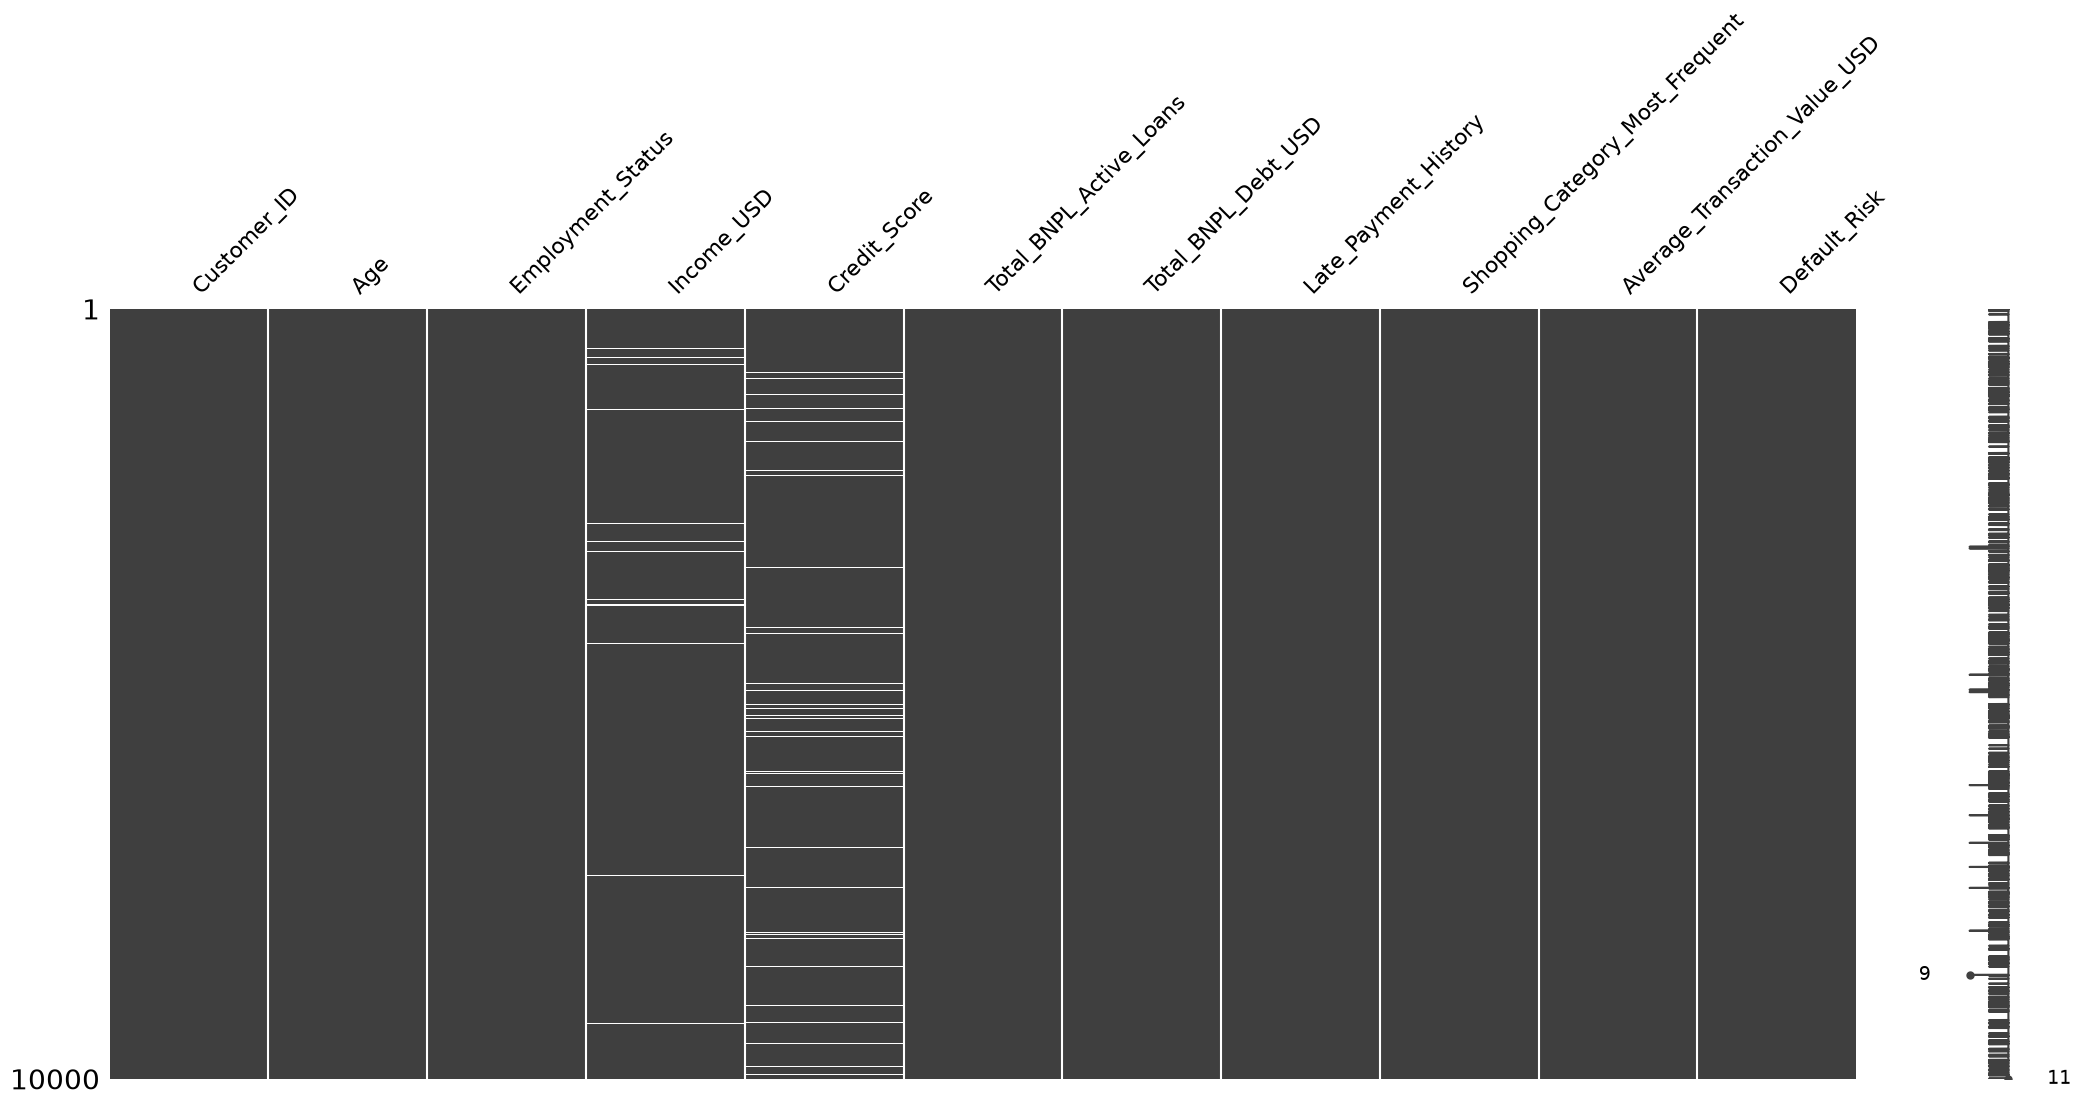

In [7]:
msno.matrix(df)
plt.show()

In [8]:
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Customer_ID                          0
Age                                  0
Employment_Status                    0
Income_USD                         305
Credit_Score                       298
Total_BNPL_Active_Loans              0
Total_BNPL_Debt_USD                  0
Late_Payment_History                 0
Shopping_Category_Most_Frequent      0
Average_Transaction_Value_USD        0
Default_Risk                         0
dtype: int64


The missing values that we observe within the "Income_USD" & "Credit_Score" appears to be 

I will use imputation of the mean of each column to fix these missing value error, this will be performed on the test set after we establish the train test split, so as to prevent potential data leakage. 

In [9]:
df.duplicated().sum()

np.int64(0)

No duplicate rows

In [10]:
df = df.drop(columns="Customer_ID")

We drop the "Customer_ID" column as this value does not provide useful information to our analysis and model building.

**Counts for Categorical Features**

In [11]:
df["Default_Risk"].value_counts()

Default_Risk
Low       8801
Medium     678
High       521
Name: count, dtype: int64

In [12]:
df["Employment_Status"].value_counts()

Employment_Status
Employed      6029
Student       1968
Freelancer    1495
Unemployed     508
Name: count, dtype: int64

In [13]:
df["Shopping_Category_Most_Frequent"].value_counts()

Shopping_Category_Most_Frequent
Fashion                 4012
Electronics             2991
Home/Furniture          1512
Travel                   971
Groceries/Essentials     514
Name: count, dtype: int64

In [14]:
df["Late_Payment_History"].value_counts()

Late_Payment_History
No     7524
Yes    2476
Name: count, dtype: int64

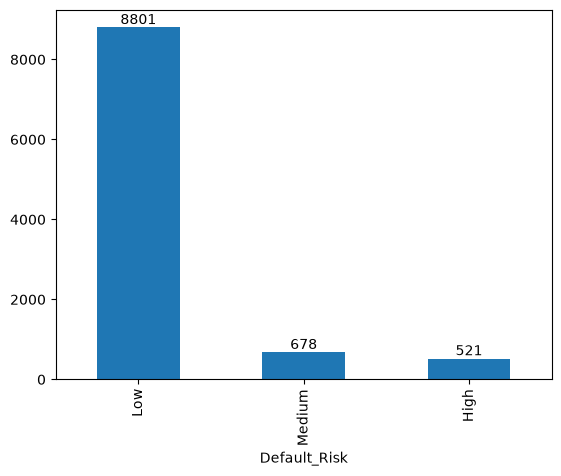

In [15]:
ax = df["Default_Risk"].value_counts().plot.bar()
ax.bar_label(ax.containers[0])
plt.show()

We have a major class imbalance issue regarding our target feature "Default Risk". The majority of the users (88.1%) have Low default risk, so I expect our baseline model to struggle with identifying the other risk types. We will need to use class imbalance methods to try and resolve this issue when we begin training our model.

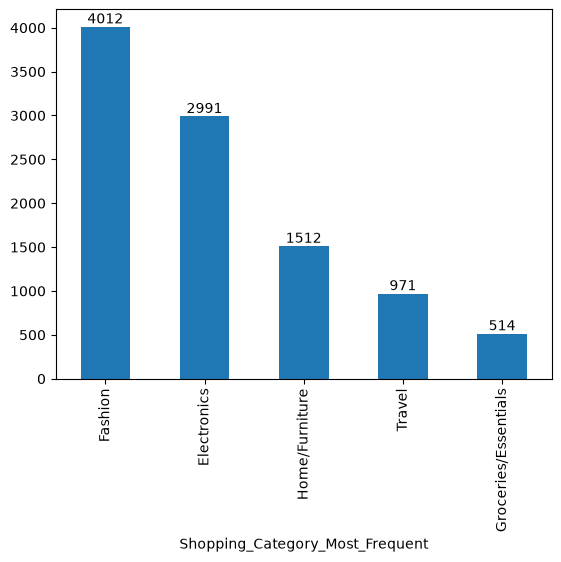

In [16]:
ax = df["Shopping_Category_Most_Frequent"].value_counts().plot.bar()
ax.bar_label(ax.containers[0])
plt.show()

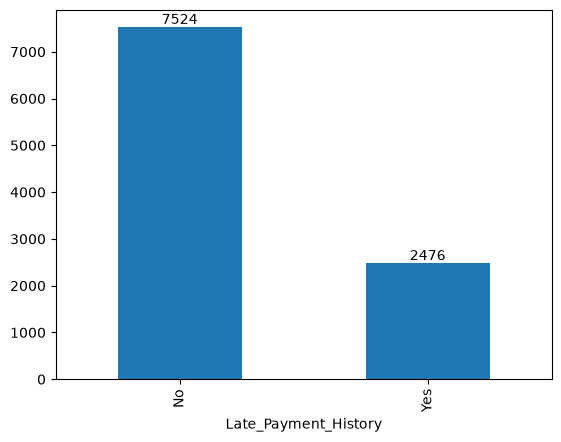

In [17]:
ax = df["Late_Payment_History"].value_counts().plot.bar()
ax.bar_label(ax.containers[0])
plt.show()

<Axes: >

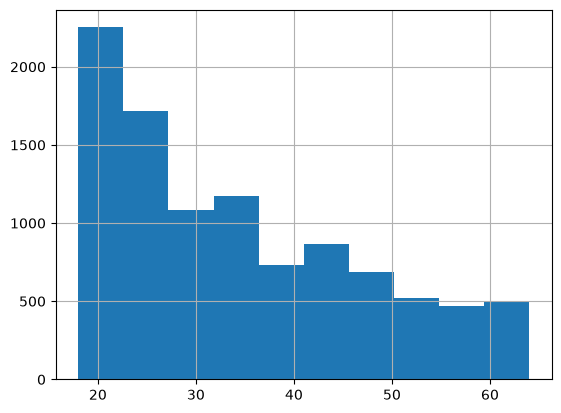

In [18]:
df["Age"].hist()

<Axes: >

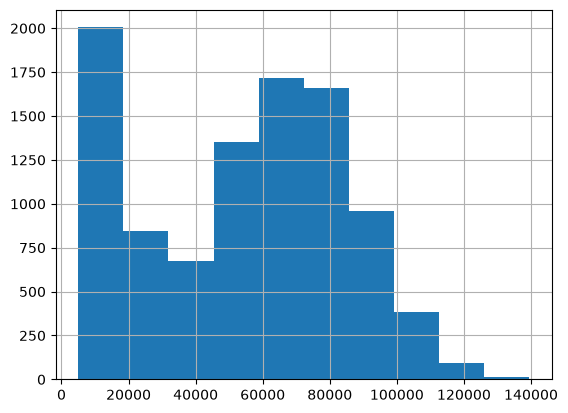

In [19]:
df["Income_USD"].hist()

<Axes: >

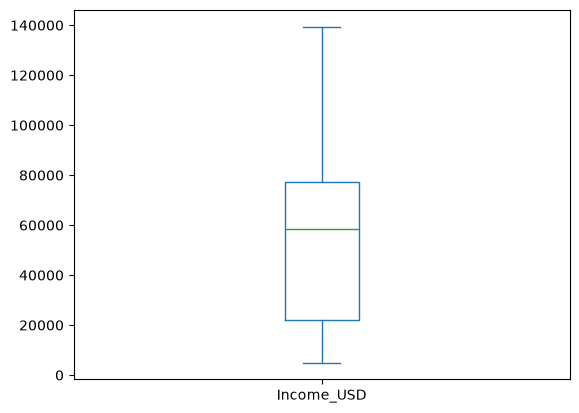

In [20]:
df["Income_USD"].plot.box()

<Axes: >

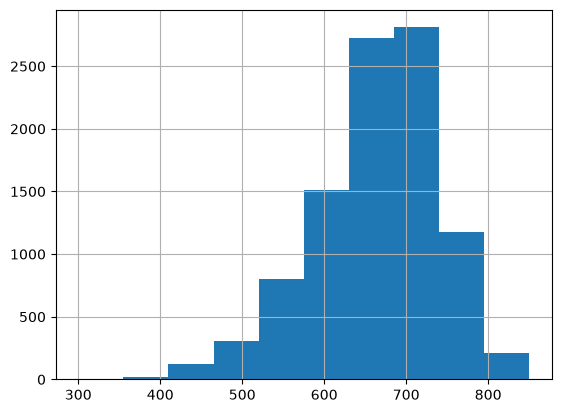

In [21]:
df["Credit_Score"].hist()

<Axes: >

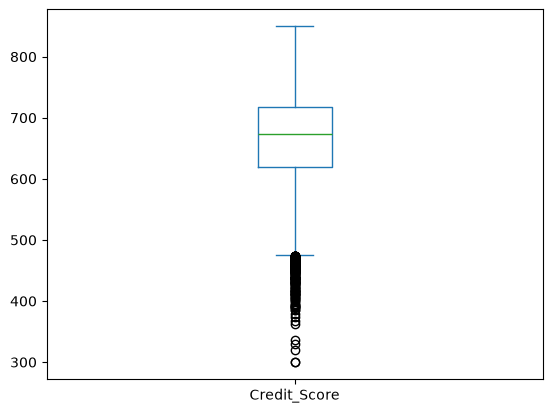

In [22]:
df["Credit_Score"].plot.box()

<Axes: >

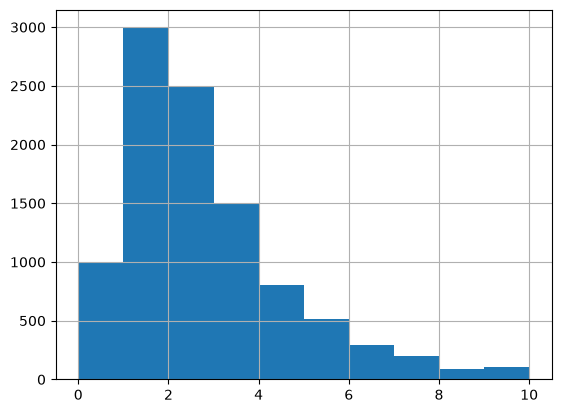

In [23]:
df["Total_BNPL_Active_Loans"].hist()

<Axes: >

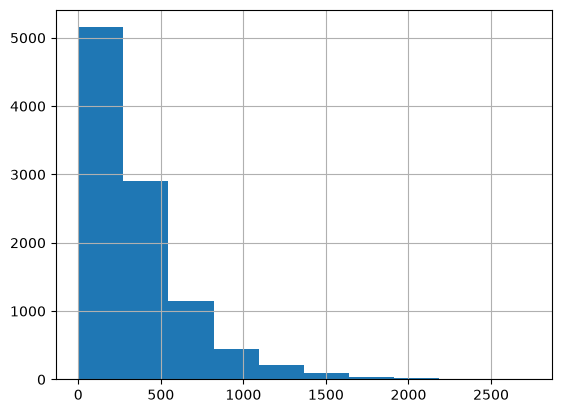

In [24]:
df["Total_BNPL_Debt_USD"].hist()

<Axes: >

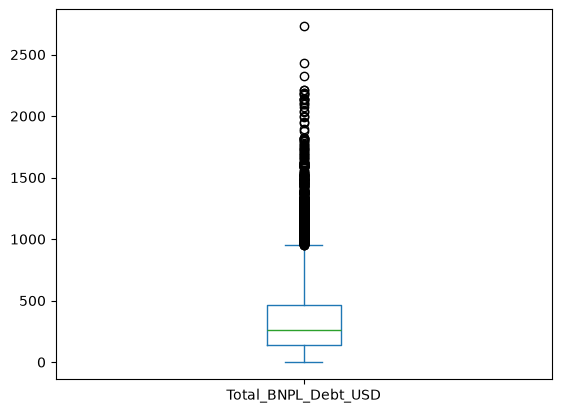

In [25]:
df["Total_BNPL_Debt_USD"].plot.box()

The distribution of Total Debt is heavily Left Skewed, Favoring those with low to no debt

<Axes: >

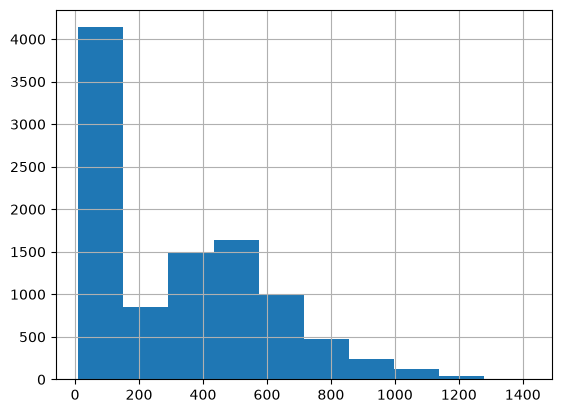

In [26]:
df["Average_Transaction_Value_USD"].hist()

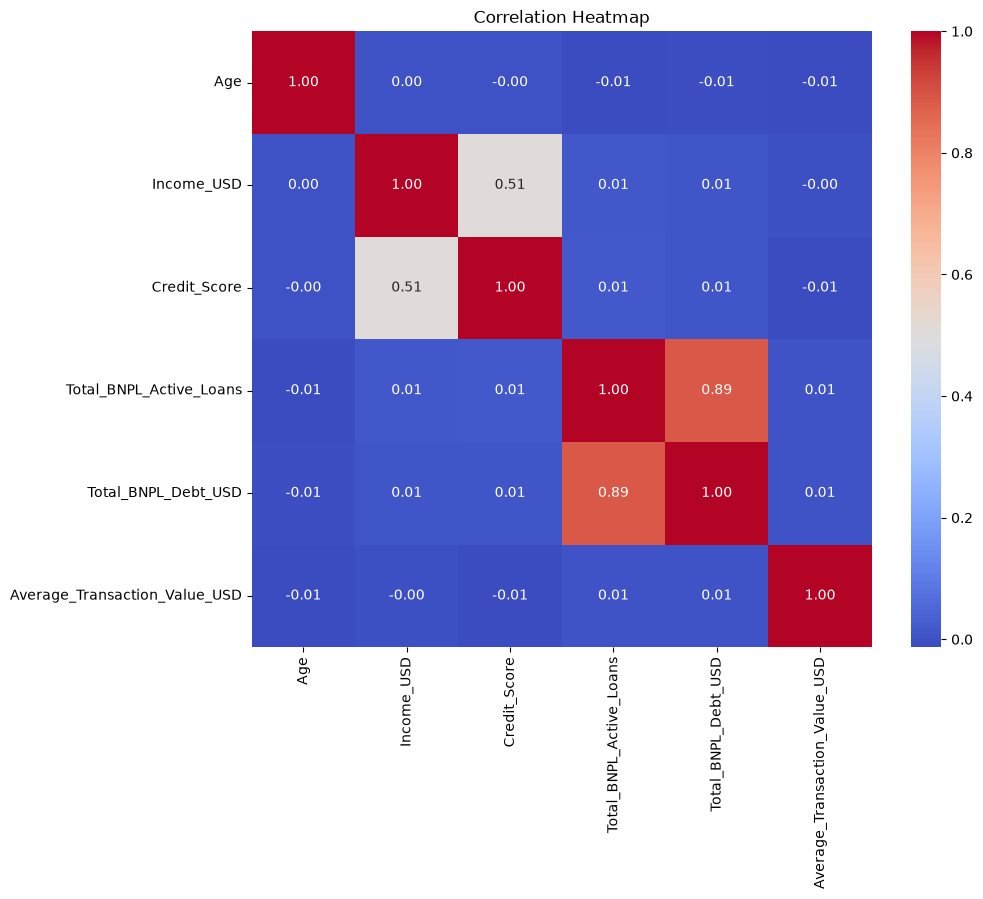

In [27]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

**DATE PREPROCESSING**

We will label encode the "Default_Risk", "Employment_Status", and "Late_Payment" columns

We will One-Hot Encode the "Shoping_Category" Feature since there is no ranking between what types of purchases customers make

In [28]:
df["Default_Risk"] = df["Default_Risk"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})

In [29]:
df['Employment_Status'].value_counts()

Employment_Status
Employed      6029
Student       1968
Freelancer    1495
Unemployed     508
Name: count, dtype: int64

In [30]:
df['Employment_Status'] = df['Employment_Status'].map({
    "Unemployed" : 0,
    "Student" : 1,
    "Freelancer" : 2,
    "Employed" : 3
})

In [31]:
df['Late_Payment_History'] = df["Late_Payment_History"].map({
    "No" : 0,
    "Yes" : 1,
})

**Train_Test_Split**

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

In [33]:
X = df.drop(columns=["Default_Risk"])
y = df['Default_Risk']

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**BASELINE MODEL + PIPELINE PREPARATION**

In [35]:
X_train


,Age,Employment_Status,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Late_Payment_History,Shopping_Category_Most_Frequent,Average_Transaction_Value_USD
7890,22,3,78013.0,726.0,1,118,0,Home/Furniture,631
4918,30,1,13595.0,574.0,4,535,0,Home/Furniture,364
4154,36,3,73153.0,641.0,4,666,0,Home/Furniture,494
5476,25,3,97659.0,742.0,2,328,0,Electronics,439
2500,36,3,62166.0,732.0,3,204,0,Electronics,446
...,...,...,...,...,...,...,...,...,...
5255,59,1,22065.0,715.0,4,594,0,Electronics,491
808,21,3,88052.0,635.0,2,418,1,Electronics,481
9244,27,3,81495.0,703.0,2,286,0,Home/Furniture,458
5272,49,0,18468.0,513.0,1,137,1,Home/Furniture,325


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [37]:
numerical_features = [
    'Age',
    'Employment_Status',
    'Income_USD',
    'Credit_Score',
    'Total_BNPL_Active_Loans',
    'Total_BNPL_Debt_USD',
    'Late_Payment_History',
    'Average_Transaction_Value_USD'
]

categorical_features = [
    'Shopping_Category_Most_Frequent'
]


In [38]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

In [39]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('logreg', LogisticRegression(max_iter=1000))
])

In [40]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Age','Employment_Status','Income_USD',...,'Late_Payment_History', 'Shopping_Category_Most_Frequent','Average_Transaction_Value_USD']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defaul

In [41]:
y_pred = model.predict(X_test)

In [42]:
base_metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred)],
    'F1': [f1_score(y_test, y_pred, average='macro')],
    'Recall': [recall_score(y_test, y_pred, average='macro')],
    'Precision': [precision_score(y_test, y_pred, average='macro')]
})

print(base_metrics)

   Accuracy        F1    Recall  Precision
0    0.9485  0.822178  0.811623   0.833673


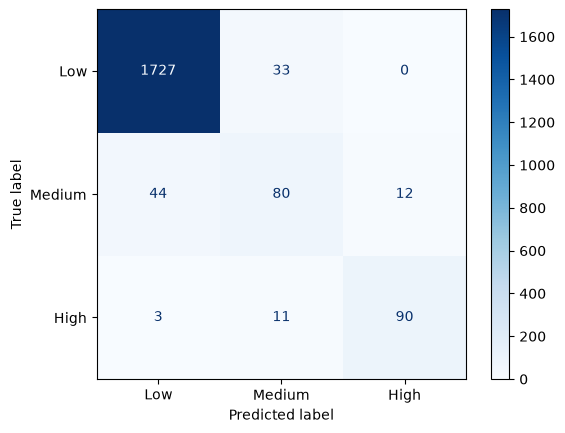

In [43]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Low', 'Medium', 'High'],
    cmap='Blues'
)

plt.show()

The model is able to predict accuracy pretty well, but as stated at the beginning accuracy is not our main/goal metric to improve due to the class imbalance found within the datasets target variable

The Models Recall and Precision are about the same so we will move on to testing the following methods to see if they will increase the models performance based on these metrics.
- Removal of Highly Correlated Features
- Log Scaling Skewed Features
- Handling Feature Imbalance via Random Over/Undersampling and SMOTE

**Testing Feature Reduction For Model Performance**

In [44]:
X_train_reduced = X_train.drop(columns=['Total_BNPL_Active_Loans'])
X_test_reduced = X_test.drop(columns=['Total_BNPL_Active_Loans'])

numerical_features_reduced = [
    col for col in numerical_features
    if col != 'Total_BNPL_Active_Loans'
]

In [45]:
preprocessor_reduced = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features_reduced),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

In [46]:
model_2 = Pipeline([
    ('preprocessor', preprocessor_reduced),
    ('logreg', LogisticRegression(max_iter=1000))
])

In [47]:
model_2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Age','Employment_Status','Income_USD',...,'Late_Payment_History', 'Shopping_Category_Most_Frequent','Average_Transaction_Value_USD']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defaul

In [48]:
y_pred_reduced = model_2.predict(X_test_reduced)

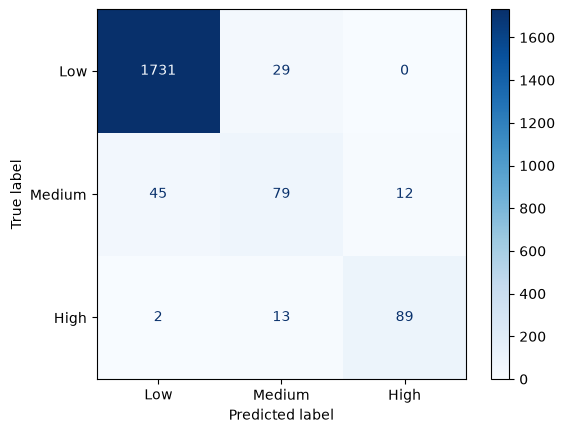

In [49]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_reduced,
    display_labels=['Low', 'Medium', 'High'],
    cmap='Blues'
)

plt.show()

In [50]:
reduced_metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_reduced)],
    'F1': [f1_score(y_test, y_pred_reduced, average='macro')],
    'Recall': [recall_score(y_test, y_pred_reduced, average='macro')],
    'Precision': [precision_score(y_test, y_pred_reduced, average='macro')]
})

print(reduced_metrics)

   Accuracy        F1    Recall  Precision
0    0.9495  0.820533  0.806725   0.835882


In [51]:
comparison = pd.concat(
    [base_metrics, reduced_metrics],
    keys=['Baseline Model', 'Feature Reduction Model Results']
)

print(comparison)

                                   Accuracy        F1    Recall  Precision
Baseline Model                  0    0.9485  0.822178  0.811623   0.833673
Feature Reduction Model Results 0    0.9495  0.820533  0.806725   0.835882


**There was no meaningful performance benefit from removing the feature, while recall & F1 scores decreased. Therefore, we will retain the feature to preserve potentially useful predictive information.**

**MODEL WITH LOG TRANSFORMATION OF SKEWED NUMERICAL COLUMNS**

In [52]:
log_features = [
    'Age',
    'Total_BNPL_Active_Loans',
    'Total_BNPL_Debt_USD',
    'Average_Transaction_Value_USD'
]

regular_num_features = [
    col for col in numerical_features
    if col not in log_features
]

In [53]:
log_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

regular_num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor_3 = ColumnTransformer([
    ('log_num', log_pipeline, log_features),
    ('regular_num', regular_num_pipeline, regular_num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

In [54]:
model_3 = Pipeline([
    ('preprocessor', preprocessor_3),
    ('logreg', LogisticRegression(max_iter=1000))
])

In [55]:
model_3.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Age','Employment_Status','Income_USD',...,'Late_Payment_History', 'Shopping_Category_Most_Frequent','Average_Transaction_Value_USD']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_num', ...), ('regular_num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are

In [56]:
y_pred_3 = model_3.predict(X_test)

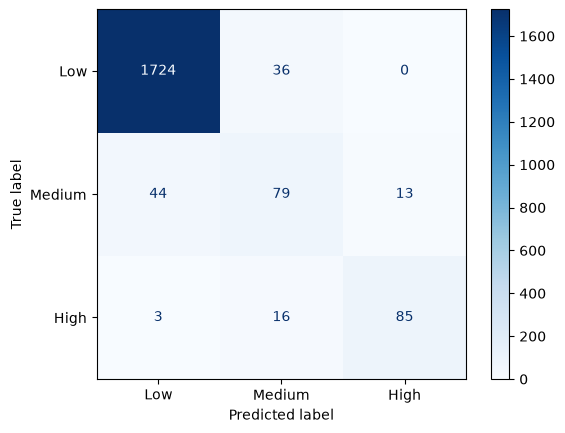

In [57]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_3,
    display_labels=['Low', 'Medium', 'High'],
    cmap='Blues'
)

plt.show()

In [58]:
log_metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_3)],
    'F1': [f1_score(y_test, y_pred_3, average='macro')],
    'Recall': [recall_score(y_test, y_pred_3, average='macro')],
    'Precision': [precision_score(y_test, y_pred_3, average='macro')]
})

print(log_metrics)

   Accuracy        F1    Recall  Precision
0     0.944  0.803279  0.792578   0.814621


In [59]:
comparison = pd.concat(
    [base_metrics, reduced_metrics, log_metrics],
    keys=['Baseline Model', 'Feature Reduction Model Results', 'Log Transformation Model']
)

print(comparison)

                                   Accuracy        F1    Recall  Precision
Baseline Model                  0    0.9485  0.822178  0.811623   0.833673
Feature Reduction Model Results 0    0.9495  0.820533  0.806725   0.835882
Log Transformation Model        0    0.9440  0.803279  0.792578   0.814621


The Log Transformation Model performed the worst among the models tested so far, indicating that applying log transformations to the skewed numerical features did not improve predictive performance for Default_Risk. The decrease in performance suggests that the original feature distributions may contain useful information that is reduced when transformed. Therefore, we will proceed to feature-balancing techniques using the untransformed dataset.

**FEATURE BALANCING TECHNIQUES**

In [60]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression

In [61]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

In [62]:
random_over_model = Pipeline([
    ('preprocessor', preprocessor),
    ('oversample', RandomOverSampler(random_state=42)),
    ('logreg', LogisticRegression(max_iter=1000))
])

random_under_model = Pipeline([
    ('preprocessor', preprocessor),
    ('undersample', RandomUnderSampler(random_state=42)),
    ('logreg', LogisticRegression(max_iter=1000))
])

smote_model = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('logreg', LogisticRegression(max_iter=1000))
])

In [63]:
random_over_model.fit(X_train, y_train)
random_under_model.fit(X_train, y_train)
smote_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](3,)","[0,1,2]"
feature_names_in_,"ndarray[object](9,)","['Age','Employment_Status','Income_USD',...,'Late_Payment_History', 'Shopping_Category_Most_Frequent','Average_Transaction_Value_USD']"
n_features_in_,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [64]:
y_pred_over = random_over_model.predict(X_test)
y_pred_under = random_under_model.predict(X_test)
y_pred_smote = smote_model.predict(X_test)

In [65]:
over_metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_over)],
    'F1': [f1_score(y_test, y_pred_over, average='macro')],
    'Recall': [recall_score(y_test, y_pred_over, average='macro')],
    'Precision': [precision_score(y_test, y_pred_over, average='macro')]
})

under_metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_3)],
    'F1': [f1_score(y_test, y_pred_under, average='macro')],
    'Recall': [recall_score(y_test, y_pred_under, average='macro')],
    'Precision': [precision_score(y_test, y_pred_under, average='macro')]
})

smote_metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, y_pred_3)],
    'F1': [f1_score(y_test, y_pred_smote, average='macro')],
    'Recall': [recall_score(y_test, y_pred_smote, average='macro')],
    'Precision': [precision_score(y_test, y_pred_smote, average='macro')]
})

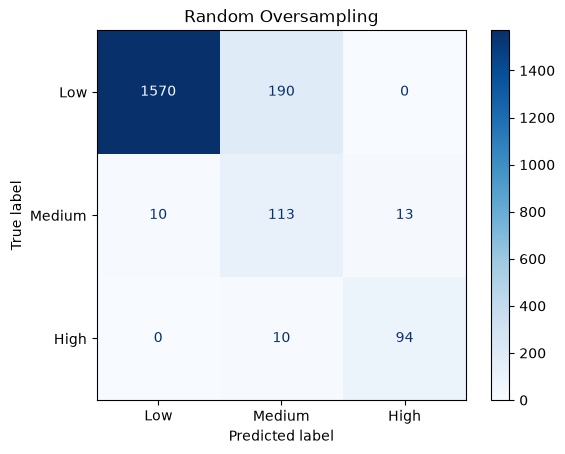

In [66]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_over,
    display_labels=['Low', 'Medium', 'High'],
    cmap='Blues'
)
plt.title("Random Oversampling")
plt.show()

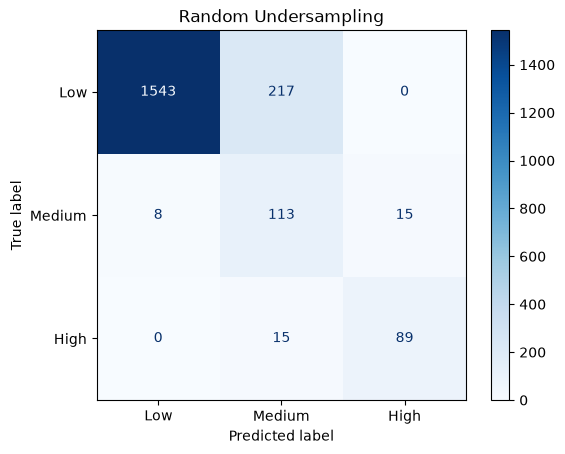

In [67]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_under,
    display_labels=['Low', 'Medium', 'High'],
    cmap='Blues'
)
plt.title("Random Undersampling")
plt.show()

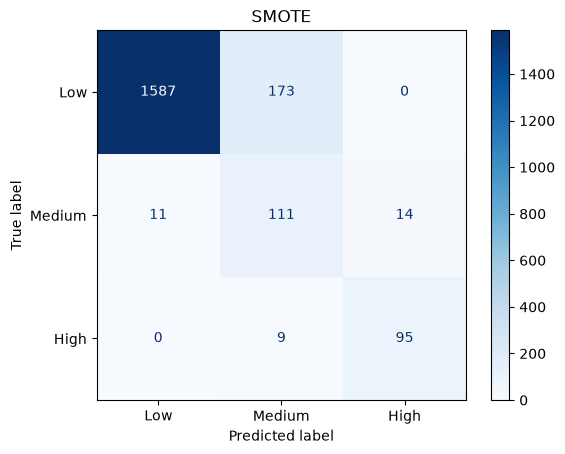

In [68]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_smote,
    display_labels=['Low', 'Medium', 'High'],
    cmap='Blues'
)
plt.title("SMOTE")
plt.show()

In [69]:
comparison = pd.concat(
    [base_metrics, reduced_metrics, log_metrics, over_metrics, under_metrics, smote_metrics],
    keys=['Baseline Model', 'Feature Reduction Model Results', 'Log Transformation Model', 'Random Oversampling', 'Random Undersampling Model', 'SMOTE Model']
)

print(comparison)

                                   Accuracy        F1    Recall  Precision
Baseline Model                  0    0.9485  0.822178  0.811623   0.833673
Feature Reduction Model Results 0    0.9495  0.820533  0.806725   0.835882
Log Transformation Model        0    0.9440  0.803279  0.792578   0.814621
Random Oversampling             0    0.8885  0.778152  0.875591   0.744399
Random Undersampling Model      0    0.9440  0.752556  0.854452   0.726049
SMOTE Model                     0    0.9440  0.784902  0.877114   0.747839


The **baseline model** demonstrated the strongest overall performance, achieving the highest **F1 score (0.8222)** and **precision (0.8337)**, while maintaining a high accuracy of **0.9485**. Although the feature reduction model achieved a marginally higher accuracy of 0.9495, its recall and F1 score were slightly lower, providing little justification for removing the feature.

The feature-balancing techniques increased recall, with **SMOTE** achieving the highest **recall at 0.8771** compared with **0.8116 for the baseline model**. However, this improvement came at the cost of lower precision and F1 performance. Therefore, the baseline model provides the strongest overall performance, while SMOTE may be preferable if maximizing recall is prioritized over precision and overall F1.

For sake of futher experimentation we will explore the performances of hyperparameter tuned verisons of the **Baseline & SMOTE** models 

**HYPERPARAMETER TUNING**

In [70]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

In [71]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('logreg', LogisticRegression(max_iter=1000))
])

baseline_param_grid = {
    'logreg__C': [0.01, 0.1, 1, 10, 100],
    'logreg__solver': ['liblinear', 'lbfgs'],
    'logreg__class_weight': [None, 'balanced']
}

baseline_grid = GridSearchCV(
    baseline_model,
    baseline_param_grid,
    scoring='recall_macro',
    n_jobs=-1
)

baseline_grid.fit(X_train, y_train)

print("Best Parameters:", baseline_grid.best_params_)
print("Best RECALL:", baseline_grid.best_score_)

Best Parameters: {'logreg__C': 100, 'logreg__class_weight': 'balanced', 'logreg__solver': 'lbfgs'}
Best RECALL: 0.859382898047901


c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
50 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return f

In [72]:
smote_model = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('logreg', LogisticRegression(max_iter=1000))
])

smote_param_grid = {
    'smote__k_neighbors': [3, 5, 7],
    'logreg__C': [0.01, 0.1, 1, 10, 100],
    'logreg__solver': ['liblinear', 'lbfgs']
}

smote_grid = GridSearchCV(
    smote_model,
    smote_param_grid,
    scoring='recall_macro',
    n_jobs=-1
)

smote_grid.fit(X_train, y_train)

print("Best Parameters:", smote_grid.best_params_)
print("Best RECALL:", smote_grid.best_score_)

Best Parameters: {'logreg__C': 100, 'logreg__solver': 'lbfgs', 'smote__k_neighbors': 7}
Best RECALL: 0.871093532004924


c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
75 fits failed out of a total of 150.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
75 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return f

In [73]:
true_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('logreg', LogisticRegression(max_iter=1000))
])

true_baseline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('logreg', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](3,)","[0,1,2]"
feature_names_in_,"ndarray[object](9,)","['Age','Employment_Status','Income_USD',...,'Late_Payment_History', 'Shopping_Category_Most_Frequent','Average_Transaction_Value_USD']"
n_features_in_,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [74]:
models = {
    'True Baseline': true_baseline,
    'Tuned Baseline': baseline_grid.best_estimator_,
    'Tuned SMOTE': smote_grid.best_estimator_
}

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("F1:", f1_score(y_test, y_pred, average='macro'))
    print("Recall:", recall_score(y_test, y_pred, average='macro'))
    print("Precision:", precision_score(y_test, y_pred, average='macro'))


True Baseline
Accuracy: 0.9485
F1: 0.8221779282982243
Recall: 0.8116233031674208
Precision: 0.8336734773918296

Tuned Baseline
Accuracy: 0.886
F1: 0.7748421744222584
Recall: 0.8738902029343206
Precision: 0.7426301914762693

Tuned SMOTE
Accuracy: 0.8965
F1: 0.7856991954575753
Recall: 0.8756058892088304
Precision: 0.7531006872266781


**Conclusions**

Hyperparameter tuning was performed on both the baseline Logistic Regression model and the SMOTE-based model to determine whether optimization could improve their performance. The original baseline model continued to demonstrate the strongest overall performance, achieving an accuracy of 0.9485, an F1 score of 0.8222, and a precision of 0.8337. Although the tuned models achieved higher recall, with the tuned baseline and tuned SMOTE models reaching 0.8739 and 0.8756 respectively, this improvement came at the cost of substantially lower accuracy, F1 score, and precision.

The tuned SMOTE model performed slightly better than the tuned baseline in accuracy, F1, recall, and precision, but neither tuned model outperformed the original baseline overall. Therefore, based on the evaluation metrics used in this study, the original baseline model remains the strongest overall model. However, if maximizing recall is the primary objective, the tuned SMOTE model may be preferable because it achieved the highest recall among the three models.

**Potential Future Reasearch**

- This project focused on evaluating and improving the predictive performance of a basic Logistic Regression model. In future work, more complex supervised learning models, such as Random Forest, XGBoost, or other ensemble methods, could be implemented to determine whether they provide meaningful improvements over Logistic Regression. This would help determine whether the patterns within the data can be effectively captured by a relatively simple model or whether more complex models are necessary to achieve stronger predictive performance.


- Another potential area of exploration is unsupervised learning. Clustering techniques could be used to determine whether naturally occurring groups within the data correspond to the existing Low, Medium, and High risk categories. This would allow us to investigate whether meaningful risk groups can be identified solely from the patterns and relationships within the features, without using the predefined risk labels during the clustering process. Comparing the resulting clusters with the known risk levels could provide additional insight into the underlying structure of the dataset.